# Superstore Sales Analysis

**Business question:** where do strong sales fail to become profit?

**Data:** Superstore sample orders, January 2014 to December 2017 (9,994 order lines, 5,009 orders, 793 customers).

**Method:** the analysis was done in SQL Server (see the `sql/` folder). Each query result was saved as a CSV in `reports/tables/`, and this notebook turns those results into charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("figures", exist_ok=True)

## 1. Did profit grow as fast as sales?

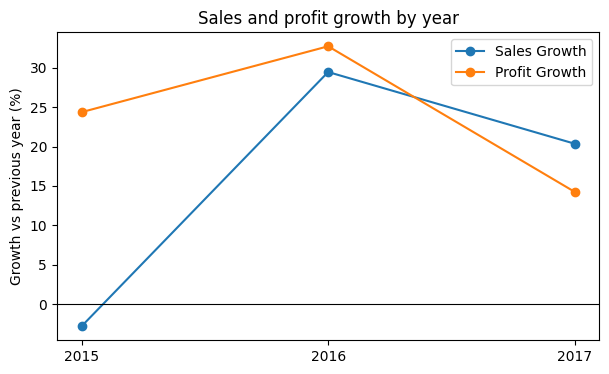

In [2]:
yearly = pd.read_csv("/content/02_yearly_growth.csv", encoding="utf-8-sig", na_values=["NULL"])
yearly = yearly.dropna()

plt.figure(figsize=(7,4))
plt.plot(yearly['Order_Year'], yearly['Sales_Growth_pct'], marker="o", label="Sales Growth")
plt.plot(yearly['Order_Year'], yearly['Profit_Growth_pct'], marker="o", label="Profit Growth")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(yearly['Order_Year'])
plt.ylabel("Growth vs previous year (%)")
plt.title("Sales and profit growth by year")
plt.legend()
plt.savefig("figures/yearly_growth.png", dpi=150, bbox_inches="tight")
plt.show()

Profit grew faster than sales in 2015 and 2016, but in 2017 sales grew 20.4% while profit grew only 14.2%, so margin slipped.


## 2. Does profit follow the sales peaks?

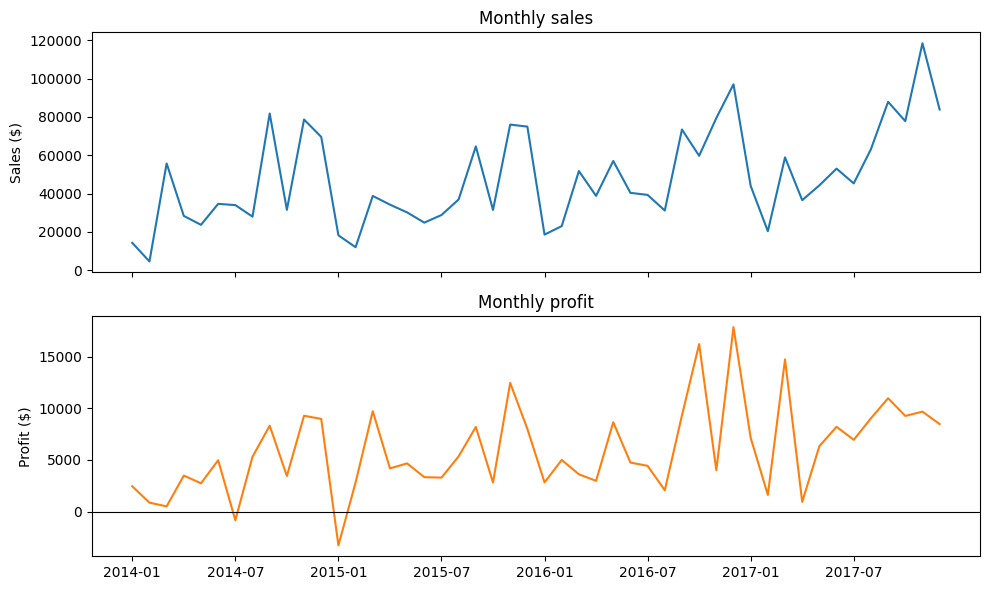

In [3]:

monthly = pd.read_csv("/content/03_monthly_trend.csv", encoding="utf-8-sig")

fig, (top, bottom) = plt.subplots(2, figsize=(10,6), sharex=True)

top.plot(monthly['Order_Month'], monthly['Total_Sales'], color="tab:blue")
top.set_ylabel("Sales ($)")
top.set_title("Monthly sales")

bottom.plot(monthly['Order_Month'], monthly['Total_Profit'], color="tab:orange")
plt.axhline(0, color="black", linewidth=0.8)
bottom.set_ylabel("Profit ($)")
bottom.set_title("Monthly profit")
bottom.set_xticks(monthly['Order_Month'][::6])


plt.tight_layout()
plt.savefig("figures/monthly_sales_profit.png", dpi=150, bbox_inches="tight")
plt.show()



Sales peak at the end of each year, but profit does not follow. The highest sales month (Nov 2017, about \$118k) earned only about \$9.7k profit, a margin of 8.2%. The most profitable month was Dec 2016 (about \$17.9k). Only two of the 48 months lost money: Jul 2014 (-\$841) and Jan 2015 (-\$3,281).


## 3. Which sub-categories lose money?

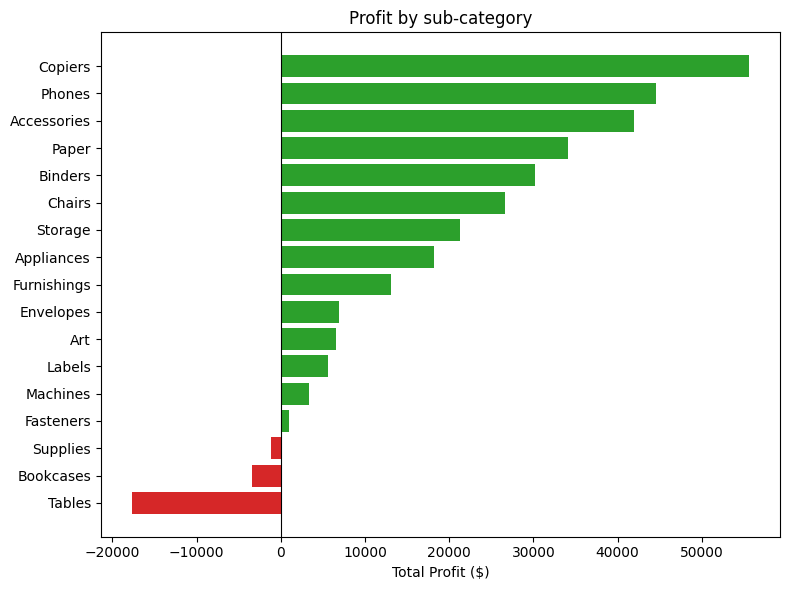

In [4]:
sub = pd.read_csv("/content/05_subcategory_profit.csv", encoding="utf-8-sig")
sub = sub.sort_values("Total_Profit")

colors = ["tab:red" if p < 0 else "tab:green" for p in sub['Total_Profit']]

plt.figure(figsize=(8,6))
plt.barh(sub['Sub_Category'], sub['Total_Profit'], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Total Profit ($)")
plt.title("Profit by sub-category")

plt.tight_layout()
plt.savefig("figures/subcategory_profit.png", dpi=150, bbox_inches="tight")
plt.show()

Three sub-categories lose money: Tables (-\$17.7k), Bookcases (-\$3.5k) and Supplies (-\$1.2k). Tables is the biggest loss, even though it ranks 4th in sales. Copiers (+\$55.6k), Phones (+\$44.5k) and Accessories (+\$41.9k) earn the most.


## 4. At what discount does profit turn negative?

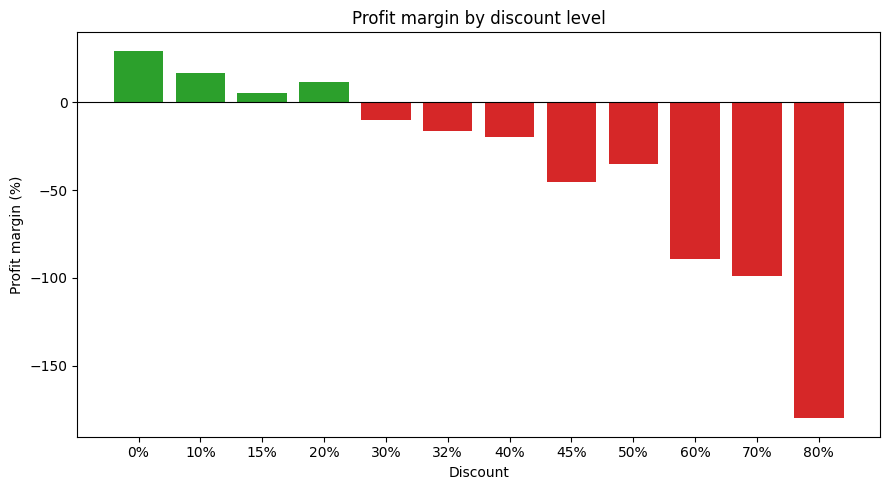

In [5]:
disc = pd.read_csv("/content/11_discount_levels.csv", encoding="utf-8-sig")

disc["Discount_Label"] = (disc["Discount"] * 100).round().astype(int).astype(str) + "%"

colors = ["tab:red" if m < 0 else "tab:green" for m in disc["Profit_Margin_pct"]]

plt.figure(figsize=(9, 5))
plt.bar(disc['Discount_Label'], disc['Profit_Margin_pct'], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Discount")
plt.ylabel("Profit margin (%)")
plt.title("Profit margin by discount level")

plt.tight_layout()
plt.savefig("figures/discount_levels.png", dpi=150, bbox_inches="tight")
plt.show()

Margin is positive up to a 20% discount (29.5% with no discount, 11.8% at 20%) and turns negative at 30% (-10.1%), falling to -180% at 80%. Some levels have few lines (for example 11 lines at 45%), so they should not be over-read. This shows an association, not proof that discounts cause the losses.


## 5. How much profit is lost on heavily discounted lines?

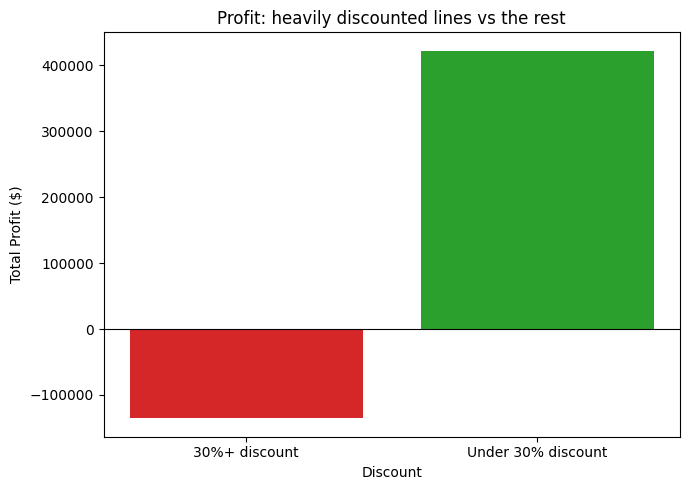

In [6]:
heavy = pd.read_csv("/content/12_heavy_discount_loss.csv", encoding="utf-8-sig")

colors = ["tab:red" if m < 0 else "tab:green" for m in heavy["Total_Profit"]]

plt.figure(figsize=(7,5))
plt.bar(heavy['Discount_Group'], heavy['Total_Profit'], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Discount")
plt.ylabel("Total Profit ($)")
plt.title("Profit: heavily discounted lines vs the rest")

plt.tight_layout()
plt.savefig("figures/heavy_discount_profit.png", dpi=150, bbox_inches="tight")
plt.show()

Lines discounted 30% or more are 13.9% of order lines and 15.8% of sales, but lost about \$135k (-37.3\% margin). All other lines earned about \$422k (21.8% margin). This is an association, not proof that discounts cause the losses.

## 6. Do Tables and Bookcases lose money only at heavy discounts?

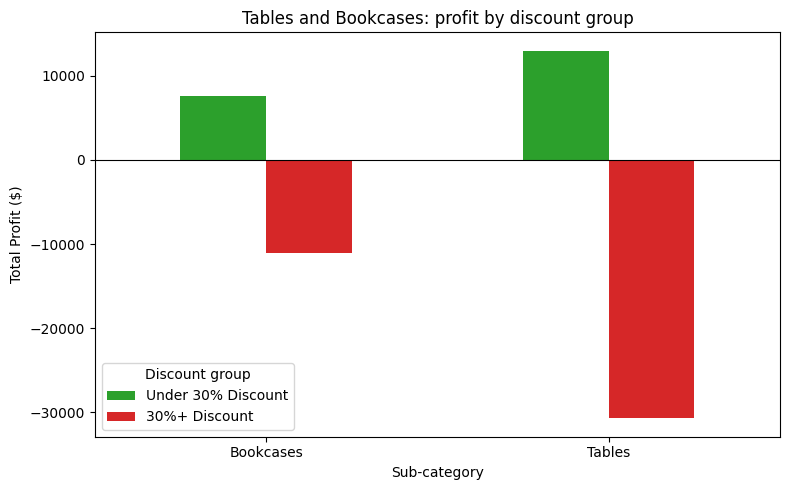

In [7]:
tb = pd.read_csv("/content/17_tables_bookcases_discount.csv", encoding="utf-8-sig")

pivot = tb.pivot(index="Sub_Category", columns="Discount_Group", values="Total_Profit")
pivot = pivot[["Under 30% Discount", "30%+ Discount"]]
pivot.plot(kind="bar", figsize=(8,5), color=["tab:green", "tab:red"], rot=0)

plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Sub-category")
plt.ylabel("Total Profit ($)")
plt.title("Tables and Bookcases: profit by discount group")
plt.legend(title="Discount group")

plt.tight_layout()
plt.savefig("figures/tables_bookcases_discount.png", dpi=150, bbox_inches="tight")
plt.show()

Both sub-categories make money under a 30% discount (Tables +\$13.0k, Bookcases +\$7.6k) but lose heavily at 30% or more (Tables -\$30.7k, Bookcases -\$11.1k). Comparing within the same product type points to discounting as the likelier driver of the losses, though it does not prove it.

## 7. Which states lose the most money?

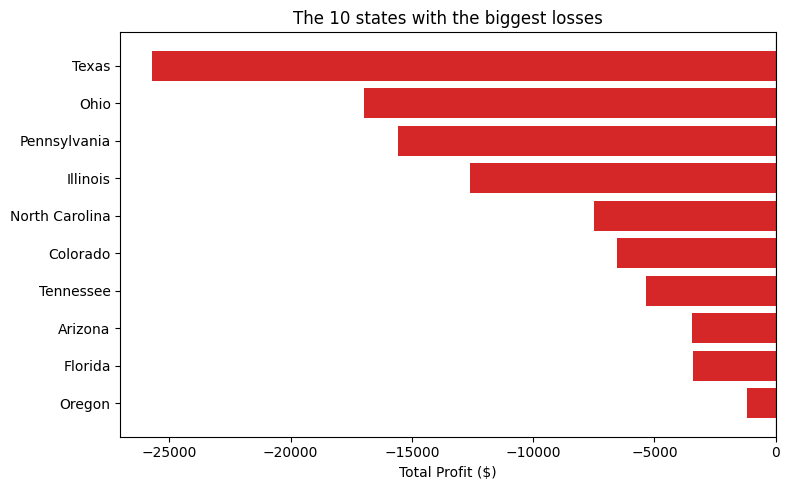

In [8]:
state = pd.read_csv("/content/09_worst_states.csv", encoding="utf-8-sig")
state = state.sort_values("Total_Profit", ascending=False)

plt.figure(figsize=(8,5))
plt.barh(state['State'], state['Total_Profit'], color="tab:red")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Total Profit ($)")
plt.title("The 10 states with the biggest losses")

plt.tight_layout()
plt.savefig("figures/worst_states.png", dpi=150, bbox_inches="tight")
plt.show()

Ten states lose money, about \$98.2k combined. Four of them account for most of it: Texas (-\$25.7k), Ohio (-\$17.0k), Pennsylvania (-\$15.6k) and Illinois (-\$12.6k) lose about \$70.9k together.

## 8. How concentrated is profit across customers?

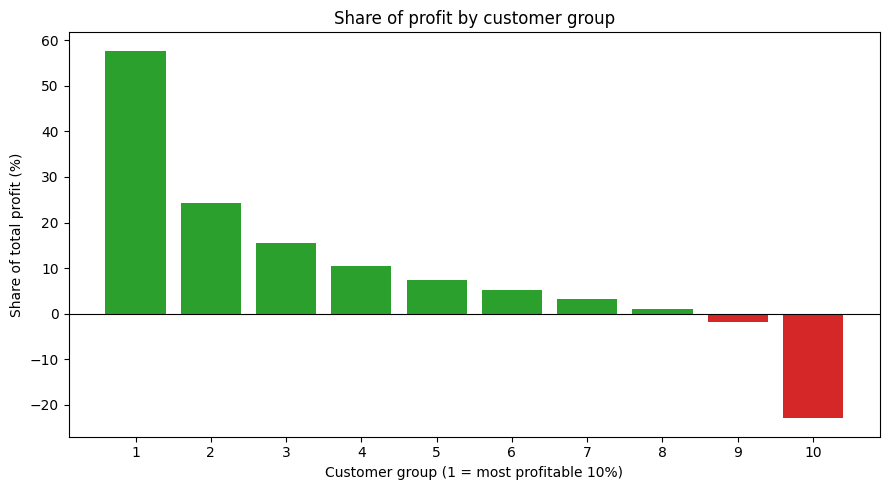

In [9]:
dec = pd.read_csv("/content/19_customer_deciles.csv", encoding="utf-8-sig")
dec["Decile_Label"] = dec["Decile"].astype(int).astype(str)

colors = ["tab:red" if s < 0 else "tab:green" for s in dec["Share_of_Profit_pct"]]

plt.figure(figsize=(9,5))
plt.bar(dec['Decile_Label'], dec['Share_of_Profit_pct'], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Customer group (1 = most profitable 10%)")
plt.ylabel("Share of total profit (%)")
plt.title("Share of profit by customer group")


plt.tight_layout()
plt.savefig("figures/customer_deciles.png", dpi=150, bbox_inches="tight")
plt.show()

Profit is concentrated in a few customers. The top 10% of customers (80 of 793) earn 57.7% of total profit, and the top 20% earn about 82%. The bottom two groups lose about \$71k combined.

## Summary

- The business earned \$286k profit on \$2.30M of sales (12.47% margin), but profit is not earned evenly.
- Lines discounted 30% or more are 13.9% of order lines, yet they lost about \$135k.
- Tables and Bookcases are profitable under a 30% discount and lose money above it.
- Ten states lose money, led by Texas, Ohio, Pennsylvania and Illinois.
- The top 10% of customers earn 57.7% of total profit.

**Recommendation:** review how discounts of 30% or more are approved, starting with Tables, Bookcases and the four worst states. These findings are associations, so a controlled test (for example, capping discounts in one region) is needed before concluding that discounts cause the losses.

**Limits:** sample data. Profit is as recorded, with no cost detail.